In [1]:
##import packages
import open3d as o3d
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os
import pandas as pd

def circle_fit_func(xy, cx, cy, r):
    """
    定义圆形拟合的函数
    xy: 点云数据的二维坐标数组 (x, y)
    cx, cy: 圆心坐标
    r: 半径
    返回值: 拟合结果数组
    """
    x, y = xy
    return (x - cx)**2 + (y - cy)**2 - r**2

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
##--------------------------读取点云数据--------------------------
GroundPCD = o3d.io.read_point_cloud(r'D:\Desktop\LiDAR_course\1119\my\ground.pcd')        # 读取地面点云数据
WoodPoint = pd.read_csv(r'D:\Desktop\LiDAR_course\1119\my\Segmentation_leafoff.txt',delimiter='\t')      # 读取枝干点云数据
WoodPoint = np.asarray(WoodPoint[['x','y','z']].values)

spth = r'D:\Desktop\LiDAR_course\1119\my\ExtractPara'      # 设置保存路径

In [3]:
##--------------------------提取距离地面点1.3m距离的点云数据--------------------------
WoodPCD = o3d.geometry.PointCloud()
WoodPCD.points = o3d.utility.Vector3dVector(WoodPoint)
dist = np.asarray(WoodPCD.compute_point_cloud_distance(GroundPCD))      # 计算枝干点距离地面的距离
index = (dist >= 1.2) & (dist <= 1.3)       # 保存1.2-1.3m处点云数据
DBHpoints = WoodPoint[index]
DBHPCD = o3d.geometry.PointCloud()
DBHPCD.points = o3d.utility.Vector3dVector(DBHpoints)
o3d.visualization.draw_geometries([DBHPCD])     # 可视化1.3m处点云数据

In [4]:
##--------------------------DBSAN聚类分析--------------------------
eps = 0.1
min_samples = 10
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(DBHpoints)
num_clusters = max(labels) + 1
clusters = [DBHpoints[labels == i] for i in range(num_clusters)]

clusters_pcd = []       #可视化点云数据
for i in range(num_clusters):
    cluster_pcd = o3d.geometry.PointCloud()
    cluster_pcd.points = o3d.utility.Vector3dVector(clusters[i])
    cluster_color = np.random.rand(3)  # 随机生成颜色
    cluster_pcd.paint_uniform_color(cluster_color)
    clusters_pcd.append(cluster_pcd)
o3d.visualization.draw_geometries(clusters_pcd)

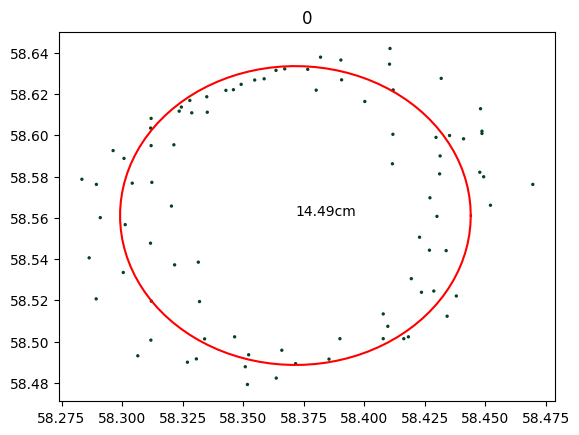

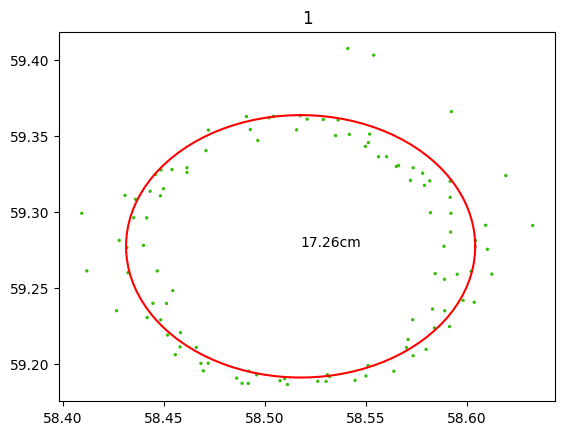

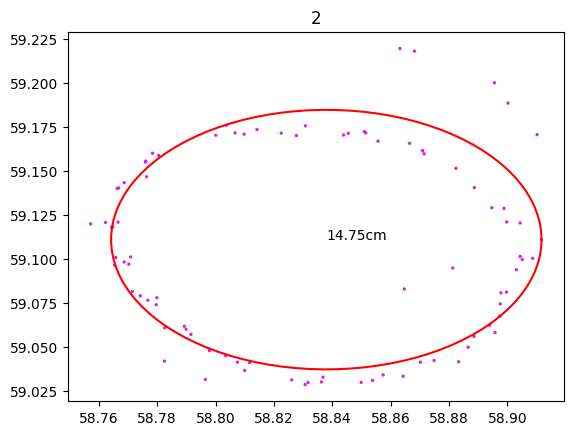

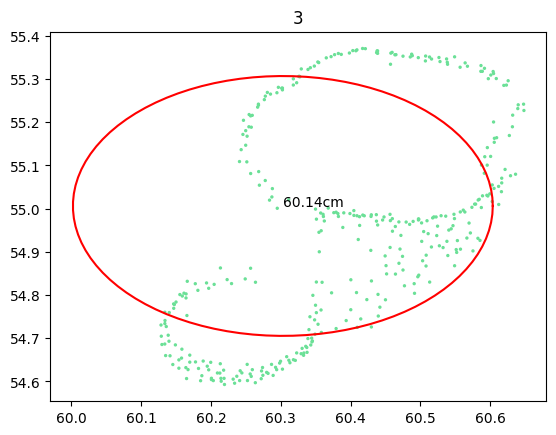

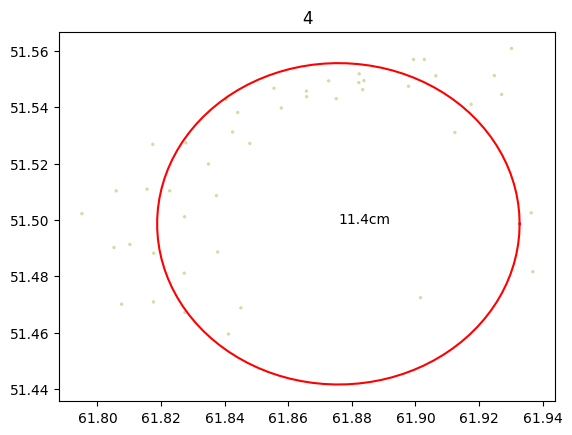

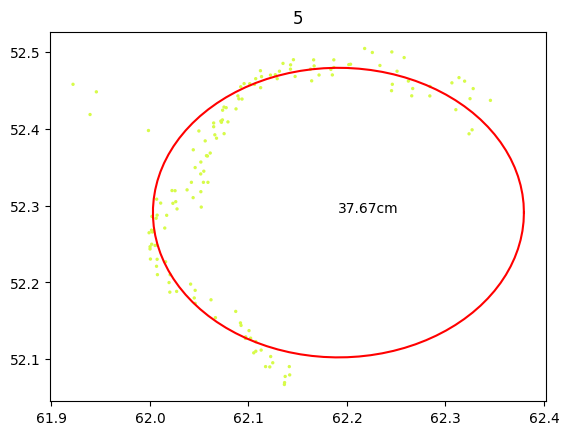

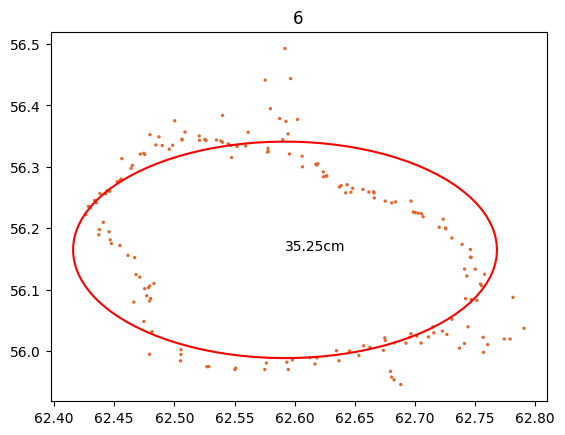

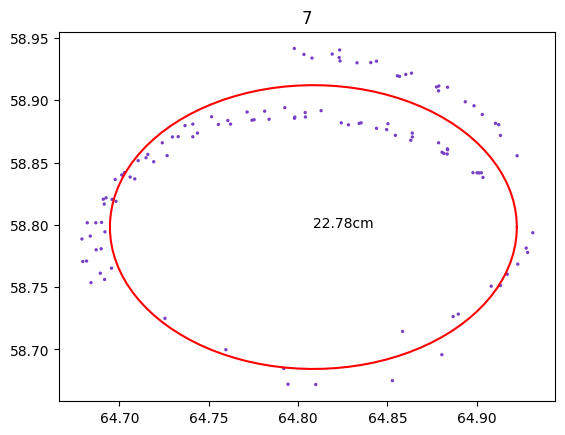

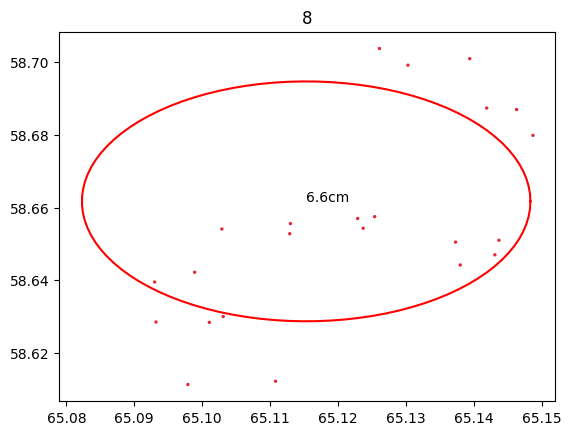

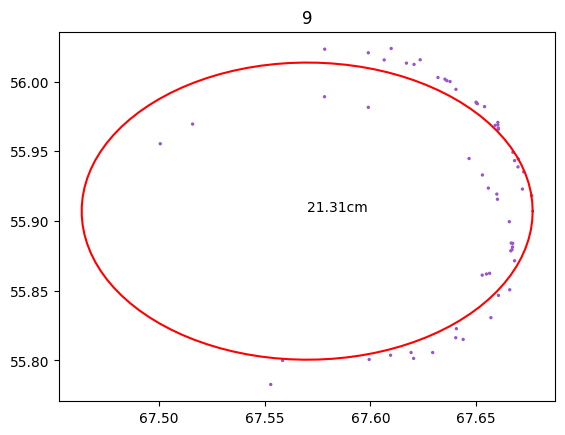

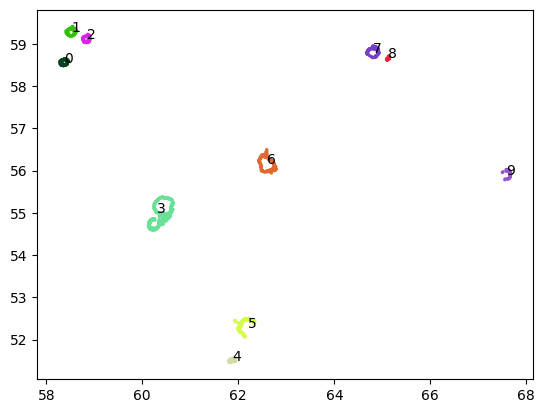

In [5]:
##--------------------------逐类点云圆形拟合--------------------------
Overall_point, Overall_color, Overall_center= [],[],[]
for i,cluster_points in enumerate(clusters):

    cluster_color = [np.random.rand(3)] * len(cluster_points)
    Overall_point.extend(cluster_points)
    Overall_color.extend(cluster_color)
    plt.scatter(cluster_points[:,0], cluster_points[:,1], color=cluster_color, s=2)

    # --------圆形拟合--------
    x, y = cluster_points[:, 0], cluster_points[:, 1]
    xy = np.vstack((x, y))
    initial_guess = [np.mean(x), np.mean(y), np.std(np.sqrt((x - np.mean(x)) ** 2 + (y - np.mean(y)) ** 2))]
    params, covariance = curve_fit(circle_fit_func, xy, np.zeros_like(x), p0=initial_guess)
    cx, cy, radius = params     # 获取中心坐标以及半径

    # --------点云可视化--------
    theta = np.linspace(0, 2 * np.pi, 100)  # 生成角度数组
    x = cx + radius * np.cos(theta)  # 计算圆周上的 x 坐标
    y = cy + radius * np.sin(theta)  # 计算圆周上的 y 坐标
    plt.plot(x,y, color='red')
    plt.text(cx, cy, str(np.round(radius * 2 * 100,2)) + 'cm')
    plt.title(str(i))
    plt.savefig(os.path.join(spth,str(i)+'.png'))
    plt.show()
    Overall_center.append([cx, cy, i])

point = np.asarray(Overall_point)
plt.scatter(point[:,0], point[:,1], color=Overall_color, s=2)
for i,xy in enumerate(Overall_center):
    plt.text(xy[0],xy[1],str(xy[2]))
plt.savefig(os.path.join(spth,'Overall.png'))
plt.show()